In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path




In [3]:

ROOT = Path.cwd().parent

print("Project root:", ROOT)
print("Data folder exists:", (ROOT / "data").exists())
print("Synthetic data folder exists:", (ROOT / "data" / "synthetic").exists())


Project root: /Users/Trisha/Downloads/epimetrics_ukm_final
Data folder exists: True
Synthetic data folder exists: True


In [4]:

cases = pd.read_csv(
    ROOT / "data/synthetic/disease_cases.csv"
)

climate = pd.read_csv(
    ROOT / "data/synthetic/climate_history.csv"
)

print("Disease cases:", cases.shape)
print("Climate data:", climate.shape)

display(cases.head())
display(climate.head())


Disease cases: (8400, 7)
Climate data: (4200, 7)


,year_month,district_id,disease_id,scenario_id,cases,cases_per_100k,data_type
0,2015-01,chn,dengue,baseline,275,3.929,synthetic_observed
1,2015-02,chn,dengue,baseline,179,2.557,synthetic_observed
2,2015-03,chn,dengue,baseline,175,2.500,synthetic_observed
3,2015-04,chn,dengue,baseline,53,0.757,synthetic_observed
4,2015-05,chn,dengue,baseline,50,0.714,synthetic_observed


,year_month,district_id,scenario_id,rainfall_mm,mean_temperature_c,relative_humidity_pct,data_type
0,2015-01,chn,baseline,14.8,28.0,67.0,synthetic_observed
1,2015-02,chn,baseline,8.6,28.3,63.7,synthetic_observed
2,2015-03,chn,baseline,9.0,31.3,70.4,synthetic_observed
3,2015-04,chn,baseline,13.3,32.5,62.5,synthetic_observed
4,2015-05,chn,baseline,23.7,31.9,69.5,synthetic_observed


In [5]:

# check dataset integrity

print("=== DISEASE CASES ===")
print("\nMissing values:")
print(cases.isnull().sum())

print("\nDuplicate records:")
print(cases.duplicated(
    subset=["year_month", "district_id", "disease_id", "scenario_id"]
).sum())

print("\n=== CLIMATE DATA ===")
print("\nMissing values:")
print(climate.isnull().sum())

print("\nDuplicate records:")
print(climate.duplicated(
    subset=["year_month", "district_id", "scenario_id"]
).sum())


=== DISEASE CASES ===

Missing values:
year_month        0
district_id       0
disease_id        0
scenario_id       0
cases             0
cases_per_100k    0
data_type         0
dtype: int64

Duplicate records:
0

=== CLIMATE DATA ===

Missing values:
year_month               0
district_id              0
scenario_id              0
rainfall_mm              0
mean_temperature_c       0
relative_humidity_pct    0
data_type                0
dtype: int64

Duplicate records:
0


In [6]:

# Verify dataset coverage

print("=== DISEASES ===")
print(cases["disease_id"].unique())

print("\n=== DISTRICTS ===")
print(cases["district_id"].unique())

print("\n=== CLIMATE SCENARIOS ===")
print(cases["scenario_id"].unique())

print("\n=== DATE RANGE ===")
print("Start:", cases["year_month"].min())
print("End:", cases["year_month"].max())

print("\n=== RECORDS PER SCENARIO ===")
print(cases.groupby("scenario_id").size())

print("\n=== SERIES COMPLETENESS ===")
series_counts = cases.groupby(
    ["disease_id", "district_id", "scenario_id"]
).size()

print("Number of series:", len(series_counts))
print("Minimum months:", series_counts.min())
print("Maximum months:", series_counts.max())
print("All series have 120 months:", series_counts.eq(120).all())


=== DISEASES ===
['dengue' 'malaria']

=== DISTRICTS ===
['chn' 'cbe' 'mdu' 'try' 'tnj']

=== CLIMATE SCENARIOS ===
['baseline' 'delayed_monsoon' 'heavy_rain_decline' 'prolonged_wet'
 'warmer' 'warm_wet' 'irregular_rain']

=== DATE RANGE ===
Start: 2015-01
End: 2024-12

=== RECORDS PER SCENARIO ===
scenario_id
baseline              1200
delayed_monsoon       1200
heavy_rain_decline    1200
irregular_rain        1200
prolonged_wet         1200
warm_wet              1200
warmer                1200
dtype: int64

=== SERIES COMPLETENESS ===
Number of series: 70
Minimum months: 120
Maximum months: 120
All series have 120 months: True


In [7]:

# Verify disease-climate alignment

merged = cases.merge(
    climate,
    on=["year_month", "district_id", "scenario_id"],
    how="left",
    validate="many_to_one",
    indicator=True
)

print("=== JOIN VERIFICATION ===")
print("Disease case rows:", len(cases))
print("Merged rows:", len(merged))

print("\n=== MATCH STATUS ===")
print(merged["_merge"].value_counts())

print("\n=== CLIMATE VALUES AFTER JOIN ===")
print(
    merged[
        ["rainfall_mm",
         "mean_temperature_c",
         "relative_humidity_pct"]
    ].isnull().sum()
)

print("\n=== SAMPLE MERGED DATA ===")
display(
    merged[
        ["year_month", "district_id",
         "disease_id", "scenario_id",
         "cases", "rainfall_mm",
         "mean_temperature_c",
         "relative_humidity_pct"]
    ].head()
)


=== JOIN VERIFICATION ===
Disease case rows: 8400
Merged rows: 8400

=== MATCH STATUS ===
_merge
both          8400
left_only        0
right_only       0
Name: count, dtype: int64

=== CLIMATE VALUES AFTER JOIN ===
rainfall_mm              0
mean_temperature_c       0
relative_humidity_pct    0
dtype: int64

=== SAMPLE MERGED DATA ===


,year_month,district_id,disease_id,scenario_id,cases,rainfall_mm,mean_temperature_c,relative_humidity_pct
0,2015-01,chn,dengue,baseline,275,14.8,28.0,67.0
1,2015-02,chn,dengue,baseline,179,8.6,28.3,63.7
2,2015-03,chn,dengue,baseline,175,9.0,31.3,70.4
3,2015-04,chn,dengue,baseline,53,13.3,32.5,62.5
4,2015-05,chn,dengue,baseline,50,23.7,31.9,69.5


In [8]:

# Chronological train-test split

# only baseline observations for historical model training
baseline_data = merged[
    merged["scenario_id"] == "baseline"
].copy()

# Convert year_month to datetime
baseline_data["year_month"] = pd.to_datetime(
    baseline_data["year_month"]
)

# Sort chronologically
baseline_data = baseline_data.sort_values(
    ["disease_id", "district_id", "year_month"]
).reset_index(drop=True)

# Chronological split
train = baseline_data[
    baseline_data["year_month"] < "2022-01-01"
].copy()

test = baseline_data[
    baseline_data["year_month"] >= "2022-01-01"
].copy()

print("=== TRAIN-TEST SPLIT ===")
print("Baseline observations:", len(baseline_data))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:",
      train["year_month"].min(),
      "to", train["year_month"].max())

print("Testing period:",
      test["year_month"].min(),
      "to", test["year_month"].max())

print("\nTraining duplicates:",
      train.duplicated(
          ["year_month", "district_id", "disease_id"]
      ).sum())


=== TRAIN-TEST SPLIT ===
Baseline observations: 1200
Training observations: 840
Testing observations: 360

Training period: 2015-01-01 00:00:00 to 2021-12-01 00:00:00
Testing period: 2022-01-01 00:00:00 to 2024-12-01 00:00:00

Training duplicates: 0


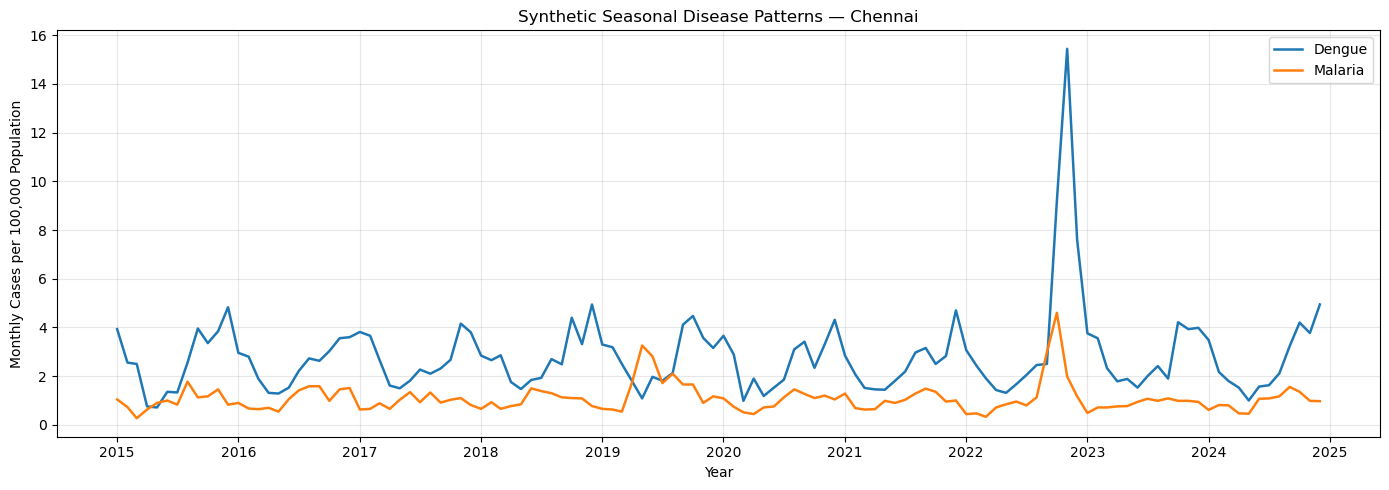

In [9]:

# baseline disease trajectories

chennai = baseline_data[
    baseline_data["district_id"] == "chn"
].copy()

plt.figure(figsize=(14, 5))

for disease in ["dengue", "malaria"]:
    subset = chennai[
        chennai["disease_id"] == disease
    ].sort_values("year_month")

    plt.plot(
        subset["year_month"],
        subset["cases_per_100k"],
        label=disease.capitalize(),
        linewidth=1.8
    )

plt.title("Synthetic Seasonal Disease Patterns — Chennai")
plt.xlabel("Year")
plt.ylabel("Monthly Cases per 100,000 Population")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:
# Observations from the time-series plot:
# 1. Dengue (blue): Cases fluctuate regularly, mostly between approximately
#    1 and 5 cases per 100,000, with a much larger spike in late 2022
#    reaching around 15.
# 2. Malaria (orange): Cases generally remain lower, although there are
#    noticeable peaks around 2019 and late 2022.
# 3. Recurring fluctuations: Both diseases show repeated rises and declines
#    rather than a single outbreak followed by permanent recovery.
#
# The late-2022 peak is particularly useful for demonstrating the recovery
# calculation. However, we cannot yet say it was caused by climate change
# or that it interrupted recovery. We must test that using the scenario
# comparisons and recovery rules.

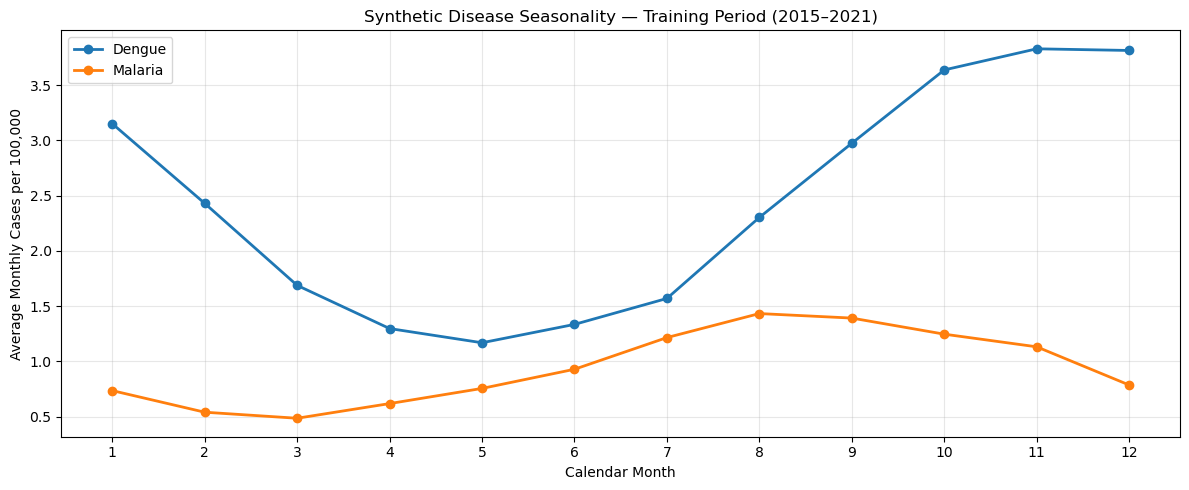

In [11]:

#  Average monthly disease seasonality


seasonal = train.copy()
seasonal["month"] = seasonal["year_month"].dt.month

monthly_avg = (
    seasonal.groupby(["disease_id", "month"])["cases_per_100k"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

for disease in ["dengue", "malaria"]:
    subset = monthly_avg[
        monthly_avg["disease_id"] == disease
    ]

    plt.plot(
        subset["month"],
        subset["cases_per_100k"],
        marker="o",
        linewidth=2,
        label=disease.capitalize()
    )

plt.xticks(range(1, 13))
plt.xlabel("Calendar Month")
plt.ylabel("Average Monthly Cases per 100,000")
plt.title("Synthetic Disease Seasonality — Training Period (2015–2021)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
#each disease needs its own seasonally adjusted recovery threshold.


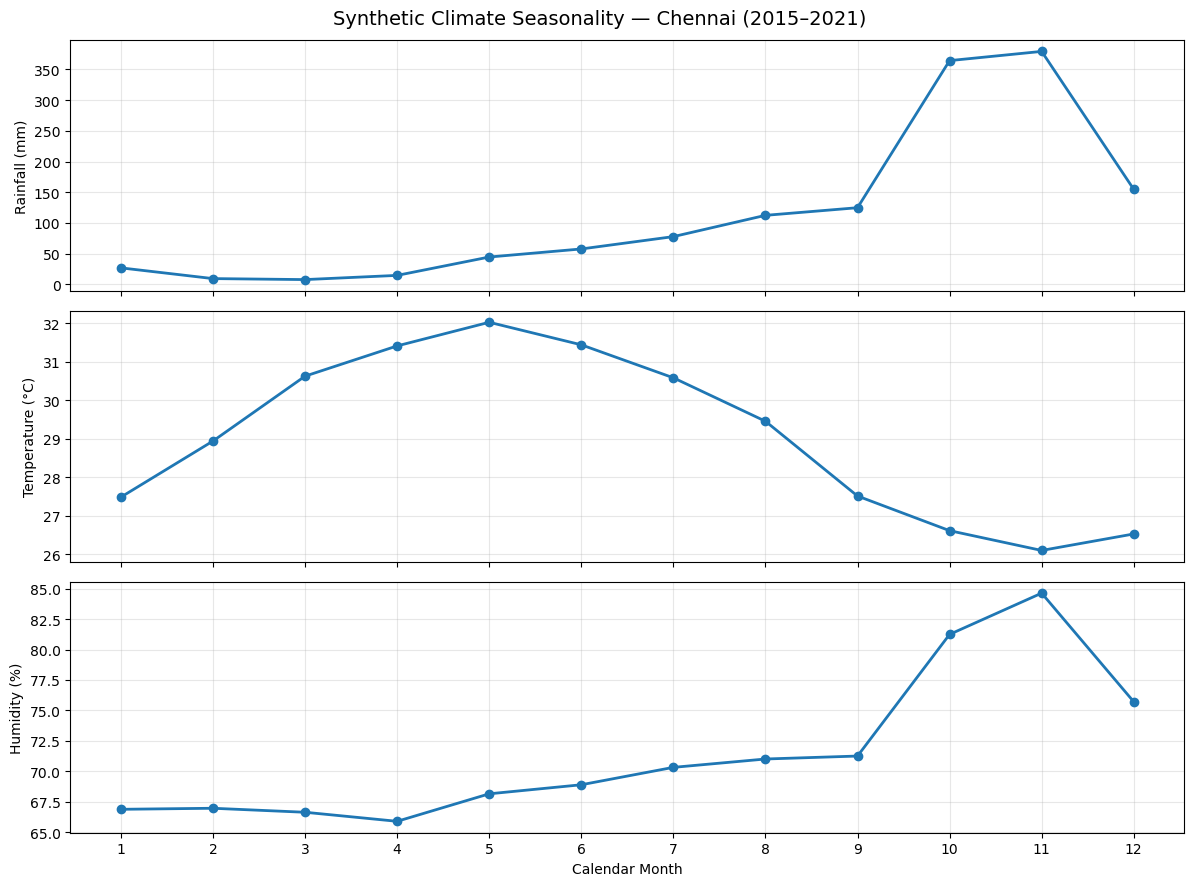

In [13]:

#  Examine climate seasonality
# Baseline climate only, training years only

climate_train = climate[
    (climate["scenario_id"] == "baseline") &
    (climate["year_month"] < "2022-01")
].copy()

climate_train["month"] = pd.to_datetime(
    climate_train["year_month"]
).dt.month

chennai_climate = climate_train[
    climate_train["district_id"] == "chn"
]

monthly_climate = chennai_climate.groupby("month")[
    [
        "rainfall_mm",
        "mean_temperature_c",
        "relative_humidity_pct"
    ]
].mean()

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 9),
    sharex=True
)

variables = [
    ("rainfall_mm", "Rainfall (mm)"),
    ("mean_temperature_c", "Temperature (°C)"),
    ("relative_humidity_pct", "Humidity (%)")
]

for ax, (column, label) in zip(axes, variables):
    ax.plot(
        monthly_climate.index,
        monthly_climate[column],
        marker="o",
        linewidth=2
    )
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[-1].set_xticks(range(1, 13))
axes[-1].set_xlabel("Calendar Month")

fig.suptitle(
    "Synthetic Climate Seasonality — Chennai (2015–2021)",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [14]:

# Explore climate-disease correlations
# Training period only; baseline scenario only

climate_variables = [
    "rainfall_mm",
    "mean_temperature_c",
    "relative_humidity_pct"
]

for disease in ["dengue", "malaria"]:

    subset = train[
        train["disease_id"] == disease
    ]

    correlations = subset[
        climate_variables + ["cases_per_100k"]
    ].corr()["cases_per_100k"].drop("cases_per_100k")

    print(f"\n=== {disease.upper()} ===")
    print(correlations.round(3))



=== DENGUE ===
rainfall_mm              0.333
mean_temperature_c      -0.584
relative_humidity_pct    0.336
Name: cases_per_100k, dtype: float64

=== MALARIA ===
rainfall_mm              0.344
mean_temperature_c      -0.155
relative_humidity_pct    0.303
Name: cases_per_100k, dtype: float64


In [15]:
# Key observations:
# * Rainfall: Both diseases show a moderate positive association with
#   rainfall.
# * Temperature: Dengue has a stronger negative correlation than malaria.
#   This does not mean increasing temperature necessarily reduces dengue
#   transmission; the relationship may be nonlinear or affected by
#   seasonality.
# * Humidity: Both diseases show positive associations.

In [16]:

# Inspect seasonally adjusted recovery thresholds

threshold_path = (
    ROOT / "data" / "derived" /
    "seasonal_baseline_thresholds.csv"
)

thresholds = pd.read_csv(threshold_path)

print("=== THRESHOLD DATASET ===")
print("Shape:", thresholds.shape)

print("\nColumns:")
print(thresholds.columns.tolist())

print("\nFirst 10 rows:")
display(thresholds.head(10))

print("\nMissing values:")
print(thresholds.isnull().sum())

print("\nDuplicate rows:")
print(thresholds.duplicated().sum())


=== THRESHOLD DATASET ===
Shape: (120, 8)

Columns:
['district_id', 'disease_id', 'calendar_month', 'training_median_cases', 'training_months', 'threshold_factor', 'threshold_cases', 'training_period']

First 10 rows:


,district_id,disease_id,calendar_month,training_median_cases,training_months,threshold_factor,threshold_cases,training_period
0,cbe,dengue,1,106.0,7,1.2,127.2,2015-01 to 2021-12
1,cbe,dengue,2,89.0,7,1.2,106.8,2015-01 to 2021-12
2,cbe,dengue,3,68.0,7,1.2,81.6,2015-01 to 2021-12
3,cbe,dengue,4,51.0,7,1.2,61.2,2015-01 to 2021-12
4,cbe,dengue,5,40.0,7,1.2,48.0,2015-01 to 2021-12
5,cbe,dengue,6,51.0,7,1.2,61.2,2015-01 to 2021-12
6,cbe,dengue,7,61.0,7,1.2,73.2,2015-01 to 2021-12
7,cbe,dengue,8,84.0,7,1.2,100.8,2015-01 to 2021-12
8,cbe,dengue,9,91.0,7,1.2,109.2,2015-01 to 2021-12
9,cbe,dengue,10,128.0,7,1.2,153.6,2015-01 to 2021-12



Missing values:
district_id              0
disease_id               0
calendar_month           0
training_median_cases    0
training_months          0
threshold_factor         0
threshold_cases          0
training_period          0
dtype: int64

Duplicate rows:
0


In [18]:
# Why this is important:
# The threshold dataset uses:
#
#     Recovery Threshold[d, r, m] = 1.2 × Training Median Cases[d, r, m]
#
# where d is the disease, r is the district and m is the calendar month.
#
# This means recovery is evaluated against a disease-specific,
# district-specific and seasonally adjusted threshold, rather than one
# fixed case count.
#
# One detail we'll verify next is whether the thresholds reproduce the
# training-period medians exactly, including any rounding rules.

In [19]:

# Independently verify seasonal thresholds

# Extract calendar month from baseline training data
train_check = train.copy()
train_check["calendar_month"] = train_check["year_month"].dt.month

# Recalculate monthly medians using training data only
calculated = (
    train_check.groupby(
        ["district_id", "disease_id", "calendar_month"]
    )["cases"]
    .median()
    .reset_index(name="calculated_median")
)

# Compare against the supplied threshold dataset
threshold_check = thresholds.merge(
    calculated,
    on=["district_id", "disease_id", "calendar_month"],
    how="left",
    validate="one_to_one"
)

threshold_check["median_difference"] = (
    threshold_check["training_median_cases"]
    - threshold_check["calculated_median"]
).abs()

threshold_check["raw_expected_threshold"] = (
    threshold_check["calculated_median"]
    * threshold_check["threshold_factor"]
)

print("Threshold rows:", len(threshold_check))

print("Maximum median difference:",
      threshold_check["median_difference"].max())

print("Threshold factors:",
      threshold_check["threshold_factor"].unique())

print("\nSample verification:")
display(
    threshold_check[
        [
            "district_id",
            "disease_id",
            "calendar_month",
            "training_median_cases",
            "calculated_median",
            "threshold_factor",
            "threshold_cases",
            "raw_expected_threshold"
        ]
    ].head(10)
)


Threshold rows: 120
Maximum median difference: 0.0
Threshold factors: [1.2]

Sample verification:


,district_id,disease_id,calendar_month,training_median_cases,calculated_median,threshold_factor,threshold_cases,raw_expected_threshold
0,cbe,dengue,1,106.0,106.0,1.2,127.2,127.2
1,cbe,dengue,2,89.0,89.0,1.2,106.8,106.8
2,cbe,dengue,3,68.0,68.0,1.2,81.6,81.6
3,cbe,dengue,4,51.0,51.0,1.2,61.2,61.2
4,cbe,dengue,5,40.0,40.0,1.2,48.0,48.0
5,cbe,dengue,6,51.0,51.0,1.2,61.2,61.2
6,cbe,dengue,7,61.0,61.0,1.2,73.2,73.2
7,cbe,dengue,8,84.0,84.0,1.2,100.8,100.8
8,cbe,dengue,9,91.0,91.0,1.2,109.2,109.2
9,cbe,dengue,10,128.0,128.0,1.2,153.6,153.6


In [20]:

#  Attach seasonal recovery thresholds

recovery_data = cases.copy()

# Convert month to datetime
recovery_data["year_month"] = pd.to_datetime(
    recovery_data["year_month"]
)

# Extract calendar month
recovery_data["calendar_month"] = (
    recovery_data["year_month"].dt.month
)

# Attach disease-, district-, and month-specific thresholds
recovery_data = recovery_data.merge(
    thresholds[
        [
            "district_id",
            "disease_id",
            "calendar_month",
            "threshold_cases"
        ]
    ],
    on=["district_id", "disease_id", "calendar_month"],
    how="left",
    validate="many_to_one"
)

# Check whether each month is below its recovery threshold
recovery_data["below_threshold"] = (
    recovery_data["cases"]
    <= recovery_data["threshold_cases"]
)

print("Total records:", len(recovery_data))

print(
    "Missing recovery thresholds:",
    recovery_data["threshold_cases"].isna().sum()
)

print("\nSample records:")
display(
    recovery_data[
        [
            "year_month",
            "district_id",
            "disease_id",
            "scenario_id",
            "cases",
            "threshold_cases",
            "below_threshold"
        ]
    ].head(10)
)


Total records: 8400
Missing recovery thresholds: 0

Sample records:


,year_month,district_id,disease_id,scenario_id,cases,threshold_cases,below_threshold
0,2015-01-01,chn,dengue,baseline,275,277.2,True
1,2015-02-01,chn,dengue,baseline,179,235.2,True
2,2015-03-01,chn,dengue,baseline,175,210.0,True
3,2015-04-01,chn,dengue,baseline,53,135.6,True
4,2015-05-01,chn,dengue,baseline,50,108.0,True
5,2015-06-01,chn,dengue,baseline,95,152.4,True
6,2015-07-01,chn,dengue,baseline,93,162.0,True
7,2015-08-01,chn,dengue,baseline,179,226.8,True
8,2015-09-01,chn,dengue,baseline,277,265.2,False
9,2015-10-01,chn,dengue,baseline,235,254.4,True
